# **Preprocessing**

Load the dataset in Python environment

In [458]:
import pandas as pd
df = pd.read_csv("/content/train_loan.csv")
df


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


# **1. Getting Insights on data**



In [459]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [460]:
# Describe for categorical values
df.describe(include="object")

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
count,614,601,611,599,614,582,614,614
unique,614,2,2,4,2,2,3,2
top,LP002990,Male,Yes,0,Graduate,No,Semiurban,Y
freq,1,489,398,345,480,500,233,422


Insights from the categorical values are:
  1. From the count, we can find there is missing values in Gender, Married, dependents, Self_Emplyed columns.
  2. In Loan_ID, count and unique values are same so it may be some sort of identifier.
  3. Most frequent Gender is 'Male', Married is 'Yes', Dependents is 0, Education is Graduate, Self_employed is No, Property_area is Semiurban, and Loan_status is Y

In [461]:
#Describe for numerical values
round(df.describe(),2)

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.00,614.00,592.00,600.00,564.00
mean,5403.46,1621.25,146.41,342.00,0.84
std,6109.04,2926.25,85.59,65.12,0.36
min,150.00,0.00,9.00,12.00,0.00
25%,2877.50,0.00,100.00,360.00,1.00
50%,3812.50,1188.50,128.00,360.00,1.00
75%,5795.00,2297.25,168.00,360.00,1.00
max,81000.00,41667.00,700.00,480.00,1.00


From the info() and describe(), following insights are getting:
1. There is five numerical (ApplicantIncome, CoapplicantIncome, LoanAmount, Loan_Amount_Term, Credit_History) and eight categorical columns are in the data.
2. Majority of 'Dependents' data looks like numerical but from the info() data, it is confirmed as categorical data. There is a + sign along with the number so it is always consider as categorical data.
3. From describe(), following:
  
    ApplicantIncome :- Mean (5403.46) > Median (3812.50) -> Positively skewed (Right Skewed), No missing values, std deviation(6109.04) > mean(5403.4) -> data is widely spread from the average, Difference between 75%(5795.00) value and max(81000.00) is significant compared to the min value so there is possibility of outliers.
  
    CoapplicantIncome :- Mean (1621.25) > Median (1188.50) -> Positively skewed (Right Skewed), No missing values, std deviation(2926.25) > mean(1621.25) -> data is widely spread from the average, Difference between 75%(2297.25) value and max(41667.00) is significant compared to the min value so there is possibility of outliers.
    
    LoanAmount :- Mean (146.41) > Median (128.00) -> Positively skewed (Right Skewed), 22 Missing values(614-592), std deviation(85.59) < mean(146.41) -> data is highly clustered around average value, Difference between 75%(168.00) value and max(128) is significant compared to the min(9.0) and 25%(100) values so there is possibility of outliers.
    
    Loan_Amount_Term :- Mean (342.00) < Median (360.00) -> Negatively skewed (Left Skewed), 14 Missing values(614-600), std deviation(65.12) < mean(342.00) -> data is highly clustered around average value, Difference between min(12) value and 25%(360),50%(360),75%(360) are significant compared to 75% and max values so there is possibility of outliers.
   
    Credit_History :- Mean (0.84) < Median (1.00) -> Negatively skewed (Left Skewed), 50 Missing values(614-564), std deviation(0.36) < mean(0.84) -> data is highly clustered around average value, Difference between min(0) value and (25% or 50% or 75% or max(1)) are same so there is a chance of outlier;need to check these are only binary values.

In [462]:
for i in df.select_dtypes("number").columns:
  print(f"Skewness of {i}: {round(df[i].skew(),2)}")

Skewness of ApplicantIncome: 6.54
Skewness of CoapplicantIncome: 7.49
Skewness of LoanAmount: 2.68
Skewness of Loan_Amount_Term: -2.36
Skewness of Credit_History: -1.88


Drawing box plot of all the numerical columns

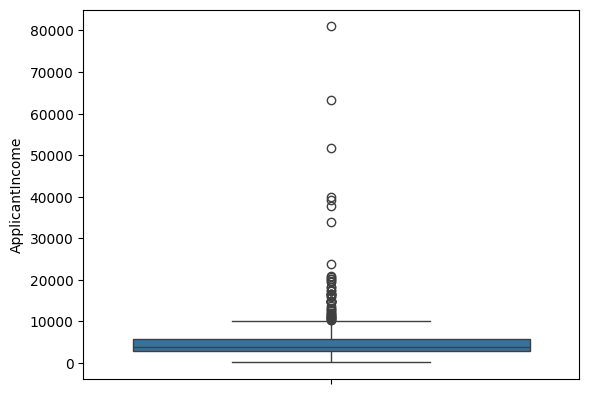

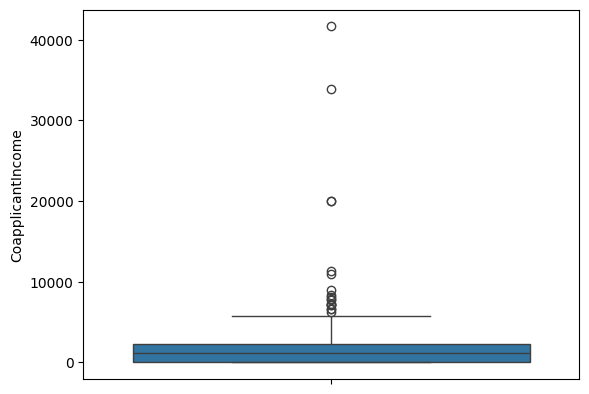

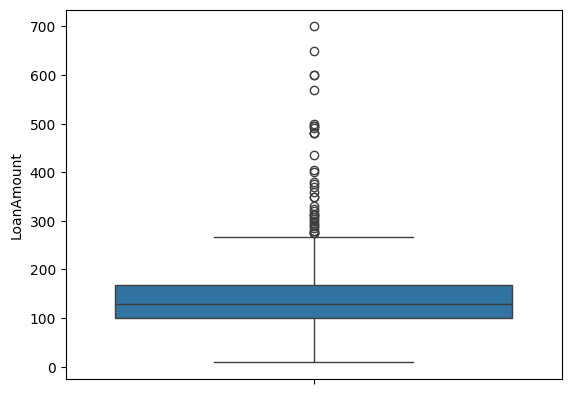

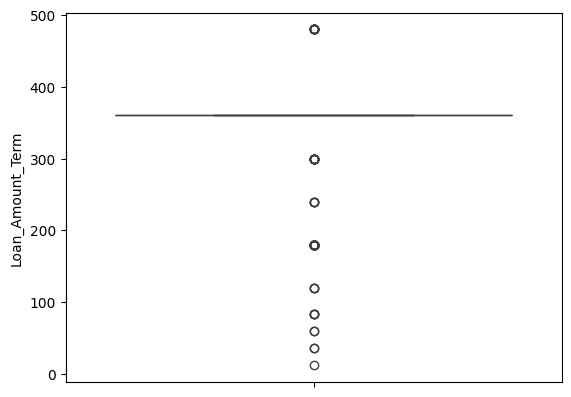

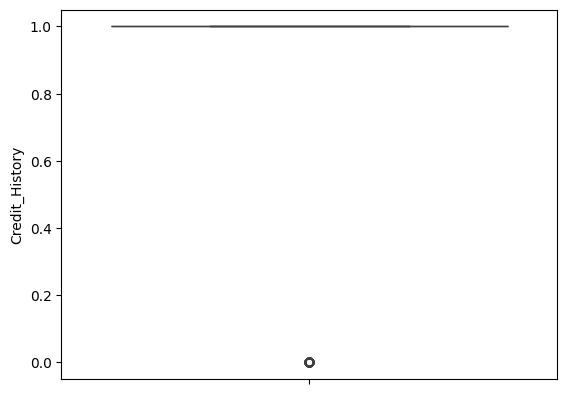

In [463]:
import seaborn as sns
import matplotlib.pyplot as plt

numerical_coumns_df = df.select_dtypes("number")
for i in numerical_coumns_df:
  sns.boxplot(numerical_coumns_df[i])
  plt.show()


All the box plots shows significant ouliers

**Drawing KDE plot**

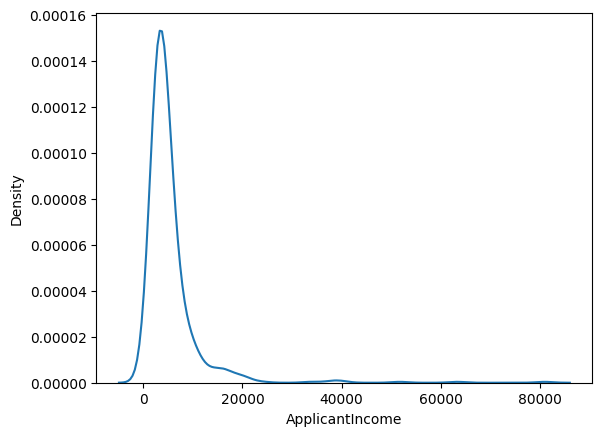

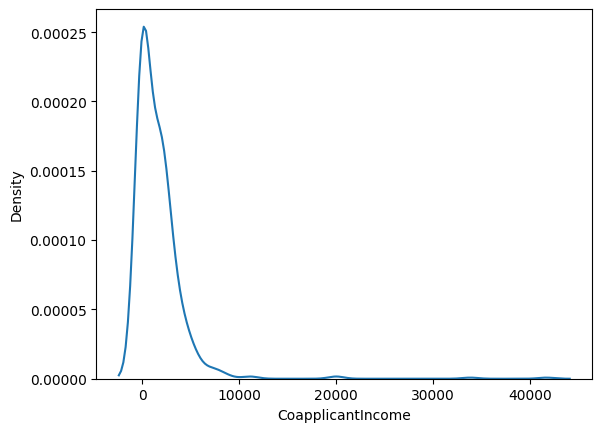

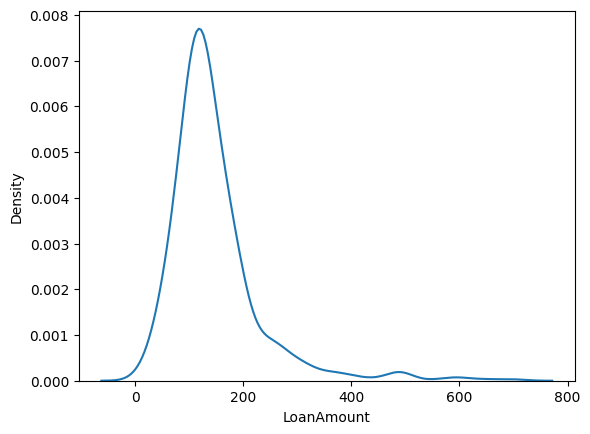

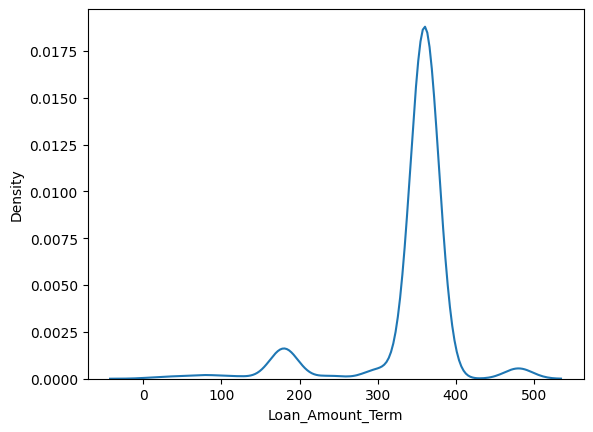

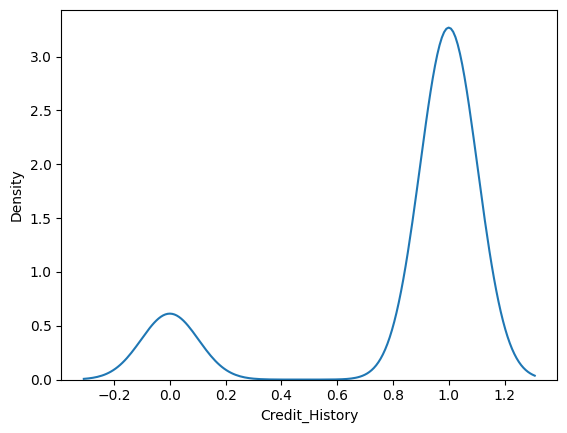

In [464]:
numerical_coumns_df = df.select_dtypes("number")
for i in numerical_coumns_df:
  sns.kdeplot(numerical_coumns_df[i])
  plt.show()

In [465]:
numerical_coumns_df = df.select_dtypes("number")
numerical_coumns_df.columns

Index(['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History'],
      dtype='object')

KDE plot insights:
1. Applicant_income -> Right Skewed, Lepto kurtic
2. CoapplicantIncome -> RIght Skewed, Lepto kurtic
3. LoanAmount -> Right Skewed, Lepto kurtic
4. Loan_Amount_Term -> Left Skewed, Lepto kurtic
5. Credit_History -> Left Skewed, Lepto kurtic

# **A. Missing Value Handling**

Checking duplicates

In [466]:
df.duplicated().sum() # There is no duplicate in the data

np.int64(0)

In [467]:
round(df.isna().mean() * 100,2) # Getting percentage of missing value of each column

,0
Loan_ID,0.00
Gender,2.12
Married,0.49
Dependents,2.44
Education,0.00
Self_Employed,5.21
ApplicantIncome,0.00
CoapplicantIncome,0.00
LoanAmount,3.58
Loan_Amount_Term,2.28


In [468]:
round(df.select_dtypes("number").isna().mean() * 100,2)

,0
ApplicantIncome,0.00
CoapplicantIncome,0.00
LoanAmount,3.58
Loan_Amount_Term,2.28
Credit_History,8.14


In [469]:
print(round(df["LoanAmount"].isna().mean()*100,2)) #Getting loan amount missing values percentage

3.58


In [470]:
def fillNumericalMissingValues(*column_names):
  for i in column_names:
    df[i] = df[i].fillna(df[i].median())
fillNumericalMissingValues("LoanAmount","Loan_Amount_Term","Credit_History")

Percentage of missing values are minimal so using imputation with median values. Median value is choosing because it will not affect extreame values.

In [471]:
round(df.select_dtypes("number").isna().mean() * 100,2)

,0
ApplicantIncome,0.0
CoapplicantIncome,0.0
LoanAmount,0.0
Loan_Amount_Term,0.0
Credit_History,0.0


Percentage of missing values in categorical columns

In [472]:
round(df.select_dtypes("object").isna().mean() * 100,2)

,0
Loan_ID,0.00
Gender,2.12
Married,0.49
Dependents,2.44
Education,0.00
Self_Employed,5.21
Property_Area,0.00
Loan_Status,0.00


In [473]:
def fillCategoricalMissingValues(*column_names):
  for i in column_names:
    df[i]=df[i].fillna(df[i].mode()[0])
fillCategoricalMissingValues("Gender","Married","Dependents","Self_Employed")

Imputing missing values with mode

In [474]:
round(df.select_dtypes("object").isna().mean() * 100,2)

,0
Loan_ID,0.0
Gender,0.0
Married,0.0
Dependents,0.0
Education,0.0
Self_Employed,0.0
Property_Area,0.0
Loan_Status,0.0


In [475]:
round(df.isna().mean() * 100,2)

,0
Loan_ID,0.0
Gender,0.0
Married,0.0
Dependents,0.0
Education,0.0
Self_Employed,0.0
ApplicantIncome,0.0
CoapplicantIncome,0.0
LoanAmount,0.0
Loan_Amount_Term,0.0


# **B. Outlier Handling**

In [476]:
df.select_dtypes("number").skew()

,0
ApplicantIncome,6.539513
CoapplicantIncome,7.491531
LoanAmount,2.743053
Loan_Amount_Term,-2.402112
Credit_History,-2.021971


<Axes: ylabel='ApplicantIncome'>

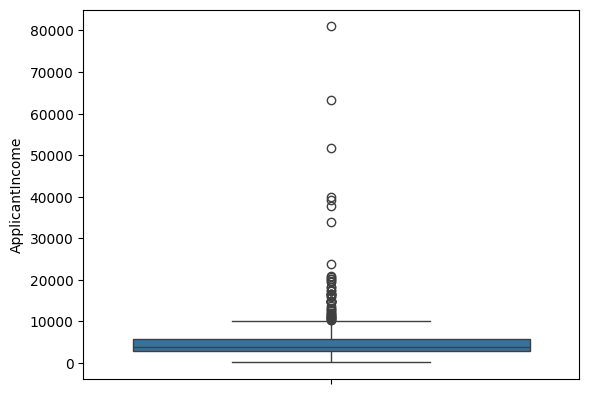

In [477]:
sns.boxplot(df["ApplicantIncome"])

In [478]:
import pandas as pd

def remove_outliers(df, *columns):
    df_filtered = df  # Make a copy of the original DataFrame

    for i in columns:
        Q1 = df[i].quantile(0.25)
        Q3 = df[i].quantile(0.75)
        IQR = Q3 - Q1

        lower_whisker = Q1 - 1.5 * IQR
        upper_whisker = Q3 + 1.5 * IQR

        # Filter out rows where column values are outliers
        df_filtered = df_filtered[(df_filtered[i] >= lower_whisker) & (df_filtered[i] <= upper_whisker)]

    return df_filtered

In [479]:
df_filtered = remove_outliers(df,"ApplicantIncome","CoapplicantIncome")

<Axes: ylabel='ApplicantIncome'>

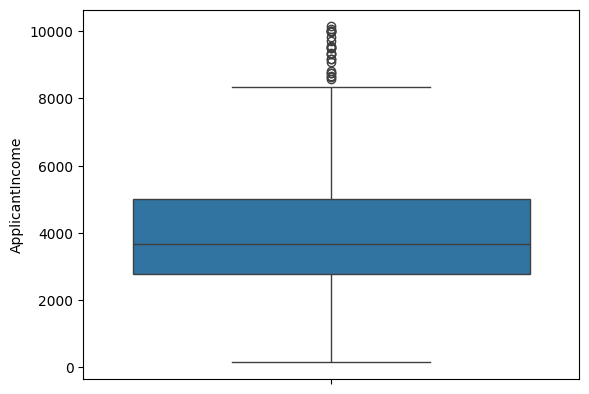

In [480]:
sns.boxplot(df_filtered["ApplicantIncome"])

<Axes: ylabel='CoapplicantIncome'>

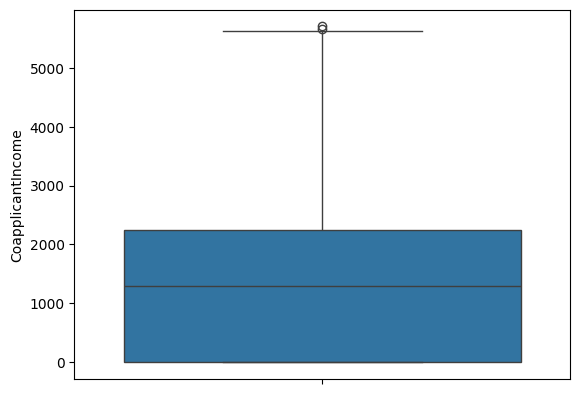

In [481]:
sns.boxplot(df_filtered["CoapplicantIncome"])

# **Encoding**

In [482]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 548 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            548 non-null    object 
 1   Gender             548 non-null    object 
 2   Married            548 non-null    object 
 3   Dependents         548 non-null    object 
 4   Education          548 non-null    object 
 5   Self_Employed      548 non-null    object 
 6   ApplicantIncome    548 non-null    int64  
 7   CoapplicantIncome  548 non-null    float64
 8   LoanAmount         548 non-null    float64
 9   Loan_Amount_Term   548 non-null    float64
 10  Credit_History     548 non-null    float64
 11  Property_Area      548 non-null    object 
 12  Loan_Status        548 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 59.9+ KB


In [483]:
df_filtered.select_dtypes("object")

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,Urban,Y
4,LP001008,Male,No,0,Graduate,No,Urban,Y
...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,Urban,Y


In [484]:
#Dropping loan id because loan id is not a feature
df_filtered.drop("Loan_ID",axis=1,inplace=True)

In [485]:
df_filtered.select_dtypes("object").nunique()

,0
Gender,2
Married,2
Dependents,4
Education,2
Self_Employed,2
Property_Area,3
Loan_Status,2


Choosing one hot encoding for feturens Gender, Married, Education, and Self_employed. Target encoding for Dependents and Property_Area

In [486]:
df_one_hot = pd.get_dummies(df_filtered, columns=['Gender','Married','Education','Self_Employed'],dtype=int,drop_first = True)
df_one_hot

,Dependents,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Gender_Male,Married_Yes,Education_Not Graduate,Self_Employed_Yes
0,0,5849,0.0,128.0,360.0,1.0,Urban,Y,1,0,0,0
1,1,4583,1508.0,128.0,360.0,1.0,Rural,N,1,1,0,0
2,0,3000,0.0,66.0,360.0,1.0,Urban,Y,1,1,0,1
3,0,2583,2358.0,120.0,360.0,1.0,Urban,Y,1,1,1,0
4,0,6000,0.0,141.0,360.0,1.0,Urban,Y,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
609,0,2900,0.0,71.0,360.0,1.0,Rural,Y,0,0,0,0
610,3+,4106,0.0,40.0,180.0,1.0,Rural,Y,1,1,0,0
611,1,8072,240.0,253.0,360.0,1.0,Urban,Y,1,1,0,0
612,2,7583,0.0,187.0,360.0,1.0,Urban,Y,1,1,0,0


Target Encoding - Dependents, Property_Area

In [487]:
# Loan_Status (Target) values converted to 0 or 1.
df_one_hot["Loan_Status"] = df_one_hot["Loan_Status"].map({'Y':1,'N':0})
#Target encoding for feature Dependents
Loan_Status_target_mean = df_one_hot.groupby('Dependents')['Loan_Status'].mean()
df_one_hot['Dependents_enc'] = df_one_hot['Dependents'].map(Loan_Status_target_mean)
#Target encoding for feature Property_Area
Property_Area_target_mean = df_one_hot.groupby('Property_Area')['Loan_Status'].mean()
df_one_hot['Property_Area_enc'] = df_one_hot['Property_Area'].map(Property_Area_target_mean)
df_one_hot.drop("Dependents", axis=1, inplace=True)
df_one_hot.drop("Property_Area", axis=1, inplace=True)
df_encoded = df_one_hot
df_encoded

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Gender_Male,Married_Yes,Education_Not Graduate,Self_Employed_Yes,Dependents_enc,Property_Area_enc
0,5849,0.0,128.0,360.0,1.0,1,1,0,0,0,0.689024,0.662857
1,4583,1508.0,128.0,360.0,1.0,0,1,1,0,0,0.666667,0.615854
2,3000,0.0,66.0,360.0,1.0,1,1,1,0,1,0.689024,0.662857
3,2583,2358.0,120.0,360.0,1.0,1,1,1,1,0,0.689024,0.662857
4,6000,0.0,141.0,360.0,1.0,1,1,0,0,0,0.689024,0.662857
...,...,...,...,...,...,...,...,...,...,...,...,...
609,2900,0.0,71.0,360.0,1.0,1,0,0,0,0,0.689024,0.615854
610,4106,0.0,40.0,180.0,1.0,1,1,1,0,0,0.690476,0.615854
611,8072,240.0,253.0,360.0,1.0,1,1,1,0,0,0.666667,0.662857
612,7583,0.0,187.0,360.0,1.0,1,1,1,0,0,0.736264,0.662857


# **Scaling**

In [488]:
df_encoded.columns

Index(['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Loan_Status', 'Gender_Male',
       'Married_Yes', 'Education_Not Graduate', 'Self_Employed_Yes',
       'Dependents_enc', 'Property_Area_enc'],
      dtype='object')

Columns for Scaling : ApplicantIncome, CoapplicantIncome, LoanAmount, Loan_Amount_Term, Credit_History, Education_Not Graduate

In [489]:
#Applying standardization
from sklearn.preprocessing import StandardScaler
std = StandardScaler()
num_columns = ["ApplicantIncome","CoapplicantIncome","LoanAmount","Loan_Amount_Term","Credit_History","Education_Not Graduate"]
df_encoded[num_columns] = std.fit_transform(df_encoded[num_columns])
df_scaled = df_encoded
df_scaled

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Gender_Male,Married_Yes,Education_Not Graduate,Self_Employed_Yes,Dependents_enc,Property_Area_enc
0,0.902588,-0.933096,-0.048562,0.262394,0.410419,1,1,0,-0.560490,0,0.689024,0.662857
1,0.238250,0.101980,-0.048562,0.262394,0.410419,0,1,1,-0.560490,0,0.666667,0.615854
2,-0.592435,-0.933096,-1.252014,0.262394,0.410419,1,1,1,-0.560490,1,0.689024,0.662857
3,-0.811258,0.685412,-0.203846,0.262394,0.410419,1,1,1,1.784154,0,0.689024,0.662857
4,0.981826,-0.933096,0.203775,0.262394,0.410419,1,1,0,-0.560490,0,0.689024,0.662857
...,...,...,...,...,...,...,...,...,...,...,...,...
609,-0.644911,-0.933096,-1.154961,0.262394,0.410419,1,0,0,-0.560490,0,0.689024,0.615854
610,-0.012058,-0.933096,-1.756687,-2.520676,0.410419,1,1,1,-0.560490,0,0.690476,0.615854
611,2.069115,-0.768362,2.377753,0.262394,0.410419,1,1,1,-0.560490,0,0.666667,0.662857
612,1.812511,-0.933096,1.096659,0.262394,0.410419,1,1,1,-0.560490,0,0.736264,0.662857
